# Did the mentor program work? Analysis notebook

Runs the SQL in DuckDB on the synthetic data, then shows the parallel-trends check, the naive comparison against difference-in-differences, and the placebo test. Run `python data/generate.py` first.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from run_analysis import build, bootstrap_did, true_effect

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = Path('images'); IMG.mkdir(exist_ok=True)
con = build()
est = con.table('estimates').df().merge(bootstrap_did(con), on='metric').merge(true_effect(con), on='metric')
con.execute('SELECT study_group, COUNT(*) AS members FROM study_groups GROUP BY 1').df()

,study_group,members
0,comparison,5078
1,mentor_engaged,12061


## 1. Parallel trends

Before launch the two groups sit at very different levels but move together. That is the assumption difference-in-differences needs.

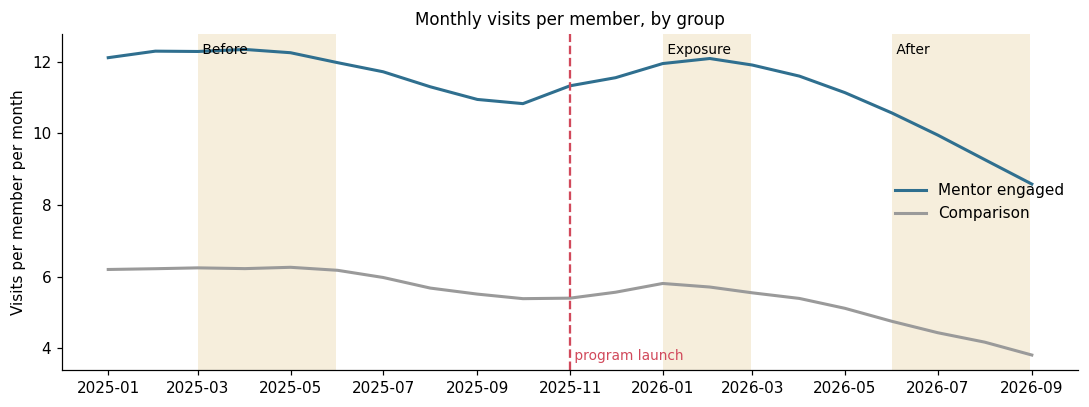

In [2]:
tr = con.table('monthly_trend').df()
tr['month'] = pd.to_datetime(tr['month'])
fig, ax = plt.subplots(figsize=(10, 3.8))
for g, color, label in [('mentor_engaged', '#2f6f8f', 'Mentor engaged'), ('comparison', '#9a9a9a', 'Comparison')]:
    s = tr[tr.study_group == g]
    ax.plot(s.month, s.avg_visits, color=color, lw=2, label=label)
for start, end, name in [('2025-03-01', '2025-05-31', 'Before'), ('2026-01-01', '2026-02-28', 'Exposure'),
                         ('2026-06-01', '2026-08-31', 'After')]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='#f1e3c6', alpha=0.6, lw=0)
    ax.text(pd.Timestamp(start), ax.get_ylim()[1] * 0.98, f' {name}', va='top', fontsize=9)
ax.axvline(pd.Timestamp('2025-11-01'), color='#d1495b', ls='--')
ax.text(pd.Timestamp('2025-11-01'), ax.get_ylim()[0] + 0.3, ' program launch', color='#d1495b', fontsize=9)
ax.set_ylabel('Visits per member per month'); ax.legend(frameon=False, loc='center right')
ax.set_title('Monthly visits per member, by group', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'parallel_trends.png', bbox_inches='tight')

## 2. Naive comparison vs difference-in-differences vs the truth

The naive number compares the groups after launch. The DiD compares how much each group changed. The truth comes from the simulated world without the program, which only synthetic data allows.

,naive_gap,baseline_gap,did_relative,ci_low,ci_high,true_effect
metric,,,,,,
visits,122.9,96.9,13.2,10.6,16.0,12.8
days_with_visit,133.6,108.4,12.1,9.0,15.1,11.6
contributions,132.5,93.1,20.4,14.4,26.6,16.9
share_of_months_active,8.3,1.8,6.5,4.5,8.4,5.6
revenue_usd,120.9,97.1,12.1,8.7,15.1,13.0


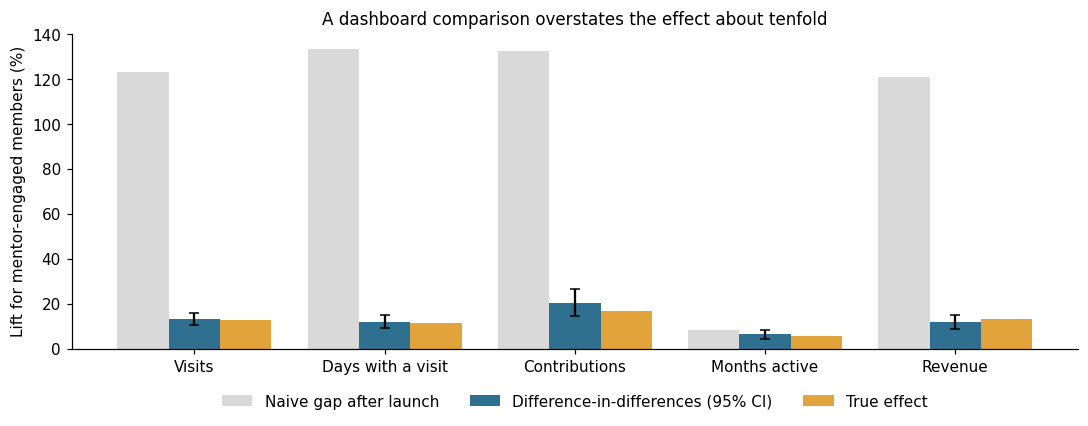

In [3]:
labels = {'visits': 'Visits', 'days_with_visit': 'Days with a visit', 'contributions': 'Contributions',
          'share_of_months_active': 'Months active', 'revenue_usd': 'Revenue'}
e = est.set_index('metric').loc[list(labels)]
x = range(len(e))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([i - 0.27 for i in x], e.naive_gap * 100, 0.27, color='#d9d9d9', label='Naive gap after launch')
ax.bar(list(x), e.did_relative * 100, 0.27, color='#2f6f8f', label='Difference-in-differences (95% CI)',
       yerr=[(e.did_relative - e.ci_low) * 100, (e.ci_high - e.did_relative) * 100], capsize=3)
ax.bar([i + 0.27 for i in x], e.true_effect * 100, 0.27, color='#e3a33b', label='True effect')
ax.set_xticks(list(x)); ax.set_xticklabels(labels.values())
ax.set_ylabel('Lift for mentor-engaged members (%)'); ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.set_title('A dashboard comparison overstates the effect about tenfold', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'naive_vs_did.png', bbox_inches='tight')
(e[['naive_gap', 'baseline_gap', 'did_relative', 'ci_low', 'ci_high', 'true_effect']] * 100).round(1)

## 3. Placebo test

Same method, fake launch in mid-2025 when the program did not exist. It should find close to nothing.

,metric,placebo_did_relative
0,visits,0.004938
1,contributions,-0.025827


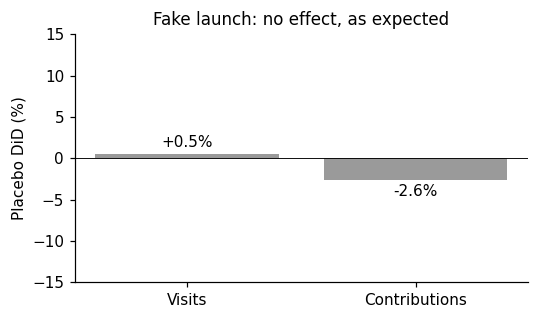

In [4]:
pl = con.table('placebo').df()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(pl.metric.str.title(), pl.placebo_did_relative * 100, color='#9a9a9a')
ax.bar_label(bars, labels=[f'{v:+.1f}%' for v in pl.placebo_did_relative * 100], padding=3)
ax.axhline(0, color='black', lw=0.6); ax.set_ylim(-15, 15)
ax.set_ylabel('Placebo DiD (%)'); ax.set_title('Fake launch: no effect, as expected', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'placebo.png', bbox_inches='tight')
pl